In [ ]:
!pip install -q xgboost

import pandas as pd, numpy as np, time, os, warnings, joblib
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from google.colab import drive

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, silhouette_score)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
drive.mount('/content/drive')

DATA_PATH = '/content/drive/MyDrive/online_retail_II.xlsx'
OUT = '/content/drive/MyDrive/retail_outputs/'               # charts and model saved here
os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
xl = pd.ExcelFile(DATA_PATH)
print(xl.sheet_names)

['Year 2009-2010', 'Year 2010-2011']


In [ ]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)
for name, s in sheets.items():
    print(name, s.shape, s.InvoiceDate.min(), '->', s.InvoiceDate.max())
raw = pd.concat(sheets.values(), ignore_index=True)
del sheets
print('Combined:', raw.shape)


Year 2009-2010 (525461, 8) 2009-12-01 07:45:00 -> 2010-12-09 20:01:00
Year 2010-2011 (541910, 8) 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Combined: (1067371, 8)


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [ ]:
print((raw.isna().mean() * 100).round(2))
print('Duplicate rows:', raw.duplicated().sum())
print('Invoices:', raw.Invoice.nunique(), '| Products:', raw.StockCode.nunique(),
      '| Customers:', raw['Customer ID'].nunique(), '| Countries:', raw.Country.nunique())
print('Negative quantity rows:', (raw.Quantity < 0).sum(), '| Price <= 0 rows:', (raw.Price <= 0).sum())

Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64
Duplicate rows: 34335
Invoices: 53628 | Products: 5305 | Customers: 5942 | Countries: 43
Negative quantity rows: 22950 | Price <= 0 rows: 6207


In [ ]:
raw[['Quantity', 'Price']].describe()

,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


In [ ]:
df = raw.rename(columns={'Customer ID': 'CustomerID'}).copy()
df['Invoice'] = df['Invoice'].astype(str); df['StockCode'] = df['StockCode'].astype(str)
print('Start rows:', len(df))

df['is_cancel'] = df['Invoice'].str.startswith('C')        # 'C' invoices = cancellations/returns
df = df.dropna(subset=['CustomerID'])                      # no ID -> cannot build customer features
df['CustomerID'] = df['CustomerID'].astype(int)
print('After dropping missing CustomerID:', len(df))
df = df.drop_duplicates()                                  # exact repeated lines
print('After dropping duplicates:', len(df))

df['Description'] = df['Description'].fillna('UNKNOWN')
df['Amount'] = df['Quantity'] * df['Price']
real_product = df['StockCode'].str.match(r'^\d{5}')        # drops POST, D, M, BANK CHARGES etc.
purch = df[~df.is_cancel & (df.Quantity > 0) & (df.Price > 0) & real_product].copy()
canc  = df[df.is_cancel & (df.Quantity < 0) & (df.Price > 0) & real_product].copy()

print('\nAmount 99.9th percentile:', round(purch.Amount.quantile(0.999)), '| max:', round(purch.Amount.max()))
print('Purchase lines:', len(purch), '| Cancellation lines:', len(canc))
print('Customers with purchases:', purch.CustomerID.nunique())
print('Purchase invoices:', purch.Invoice.nunique(), '| Cancelled invoices:', canc.Invoice.nunique())
print('Cancellation share of invoices %:', round(canc.Invoice.nunique() / purch.Invoice.nunique() * 100, 2))

Start rows: 1067371
After dropping missing CustomerID: 824364
After dropping duplicates: 797885

Amount 99.9th percentile: 833 | max: 168470
Purchase lines: 776577 | Cancellation lines: 17586
Customers with purchases: 5852
Purchase invoices: 36594 | Cancelled invoices: 7282
Cancellation share of invoices %: 19.9


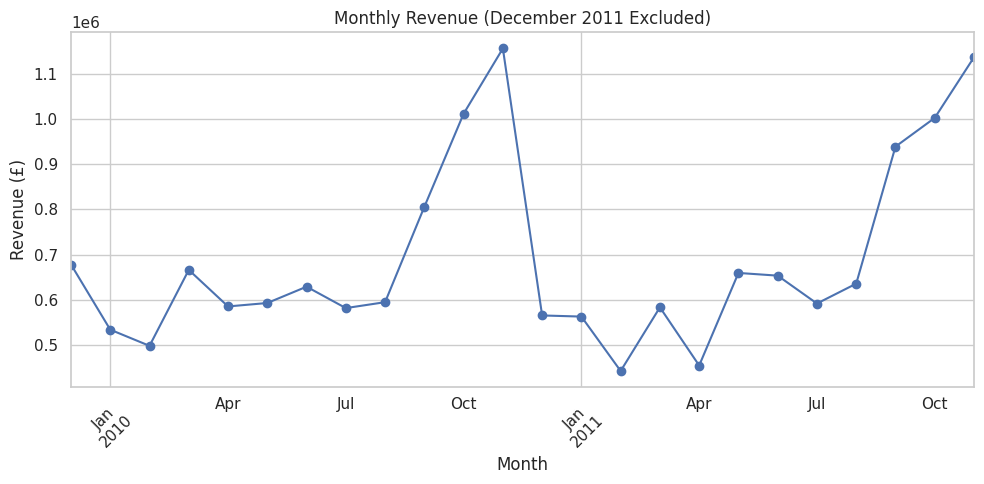

In [ ]:
monthly = purch.set_index('InvoiceDate')['Amount'].resample('MS').sum()
monthly.iloc[:-1].plot(figsize=(10, 5), marker='o')        # Dec 2011 is incomplete
plt.title('Monthly Revenue (December 2011 Excluded)'); plt.xlabel('Month'); plt.ylabel('Revenue (£)')
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig(OUT+'monthly_revenue.png', dpi=200, bbox_inches='tight'); plt.show()



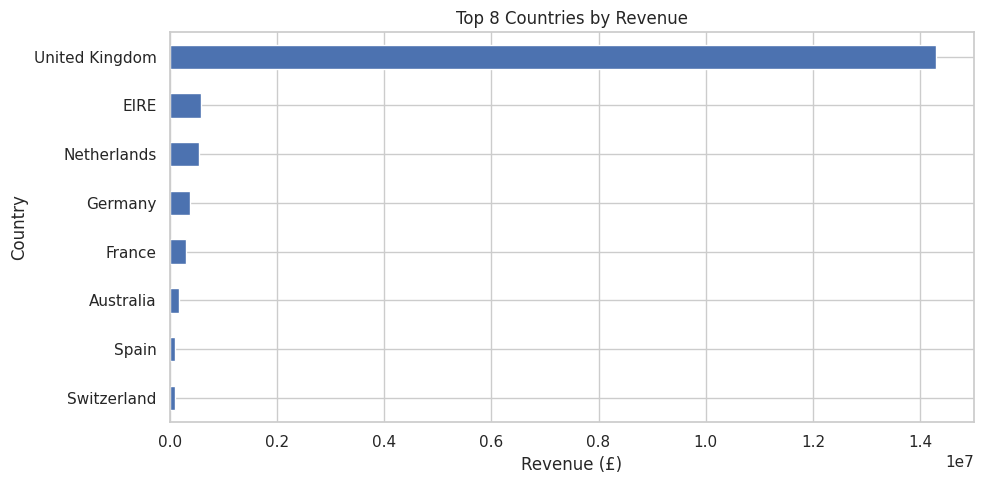

In [ ]:
purch.groupby('Country')['Amount'].sum().nlargest(8).plot.barh(figsize=(10, 5))
plt.title('Top 8 Countries by Revenue'); plt.xlabel('Revenue (£)'); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig(OUT+'top_8_countries_revenue.png', dpi=200, bbox_inches='tight'); plt.show()


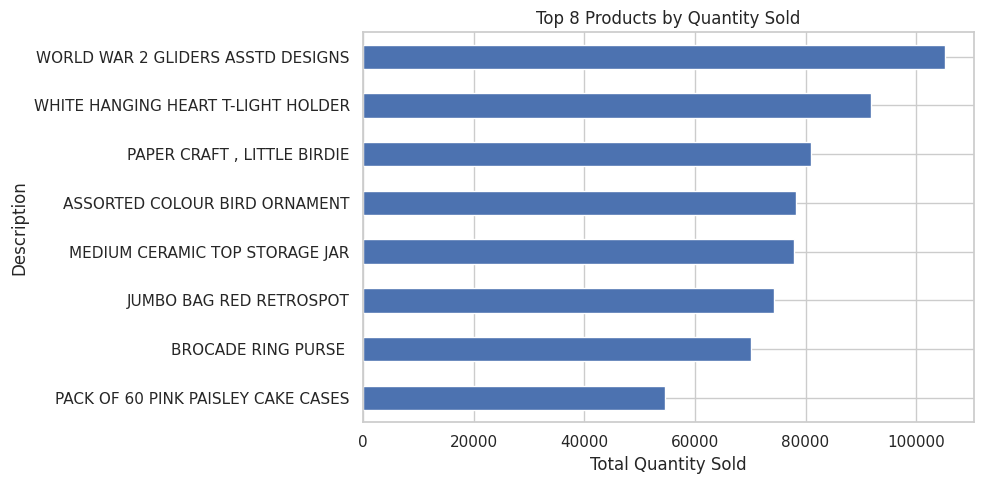

In [ ]:

purch.groupby('Description')['Quantity'].sum().nlargest(8).plot.barh(figsize=(10, 5))
plt.title('Top 8 Products by Quantity Sold'); plt.xlabel('Total Quantity Sold'); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig(OUT+'top_8_products_quantity.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
print("\nOriginal dataset shape:", df.shape)
print("Purchase dataset shape:", purch.shape)
print("Cancellation dataset shape:", canc.shape)



Original dataset shape: (797885, 10)
Purchase dataset shape: (776577, 10)
Cancellation dataset shape: (17586, 10)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 797885 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      797885 non-null  object        
 1   StockCode    797885 non-null  object        
 2   Description  797885 non-null  object        
 3   Quantity     797885 non-null  int64         
 4   InvoiceDate  797885 non-null  datetime64[ns]
 5   Price        797885 non-null  float64       
 6   CustomerID   797885 non-null  int64         
 7   Country      797885 non-null  object        
 8   is_cancel    797885 non-null  bool          
 9   Amount       797885 non-null  float64       
dtypes: bool(1), datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 61.6+ MB


In [ ]:
def build_features(purch, cutoff):
    """One row per customer, using ONLY purchases strictly before the cutoff."""
    cutoff = pd.Timestamp(cutoff)
    p = purch[purch.InvoiceDate < cutoff]
    inv = (p.groupby(['CustomerID', 'Invoice'])
             .agg(date=('InvoiceDate', 'min'), value=('Amount', 'sum')).reset_index())   # one row per invoice
    inv['days_ago'] = (cutoff - inv['date']).dt.total_seconds() / 86400
    g = inv.groupby('CustomerID')
    f = pd.DataFrame(index=g.size().index)

    f['recency'] = g['days_ago'].min()                      # days since last purchase
    f['frequency'] = g.size()                               # number of distinct invoices
    f['monetary'] = g['value'].sum()                        # total spending
    age_days = (cutoff - g['date'].min()).dt.days           # days since first purchase
    f['purchases_per_month'] = f.frequency / (age_days / 30).clip(lower=1)

    pg = p.groupby('CustomerID')
    f['n_products'] = pg['StockCode'].nunique()             # distinct products bought
    f['unique_product_ratio'] = f.n_products / pg.size()    # distinct products / purchase lines

    for d in (30, 90):                                      # recent activity
        f[f'freq_last{d}'] = inv[inv.days_ago <= d].groupby('CustomerID').size()
    f[['freq_last30', 'freq_last90']] = f[['freq_last30', 'freq_last90']].fillna(0)
    return f

In [ ]:
HORIZON = pd.Timedelta(days=90)
VAL_N = 2                                                   # two validation cutoffs (May, Jun 2011)
FIRST, LAST = df.InvoiceDate.min(), df.InvoiceDate.max()
print('Data range:', FIRST, '->', LAST)

def make_snapshot(cutoff):
    """One row per customer per cutoff; label = any real purchase in the next 90 days."""
    cutoff = pd.Timestamp(cutoff)
    assert cutoff + HORIZON <= LAST, 'Prediction window incomplete!'
    f = build_features(purch, cutoff)
    fut = purch[(purch.InvoiceDate >= cutoff) & (purch.InvoiceDate < cutoff + HORIZON)]
    f['target'] = f.index.isin(fut.CustomerID.unique()).astype(int)    # cancellations never count
    f['cutoff'] = cutoff
    return f

start = (FIRST + pd.Timedelta(days=60)).normalize()
start = start if start.day == 1 else start + pd.offsets.MonthBegin(1)
cuts = list(pd.date_range(start, LAST - HORIZON, freq='MS'))
TEST  = [cuts[-1]]
VAL   = [c for c in cuts if c + HORIZON <= TEST[0]][-VAL_N:]
TRAIN = [c for c in cuts if c + HORIZON <= VAL[0]]
unused = [c for c in cuts if c not in TRAIN + VAL + TEST]
print('Unused (label window would overlap another partition):', [str(c.date()) for c in unused])

snap = {c: make_snapshot(c) for c in TRAIN + VAL + TEST}           # takes a few minutes
stack = lambda cs: pd.concat([snap[c] for c in cs]).reset_index()
train, val, test = stack(TRAIN), stack(VAL), stack(TEST)

parts = {'train': (train, TRAIN), 'val': (val, VAL), 'test': (test, TEST)}
total = sum(len(d) for d, _ in parts.values())
rep = pd.DataFrame({n: dict(first_cutoff=str(cs[0].date()), last_cutoff=str(cs[-1].date()), n_cutoffs=len(cs),
                            label_ends=str((cs[-1] + HORIZON).date()), rows=len(d), pct_rows=round(100*len(d)/total, 1),
                            customers=d.CustomerID.nunique(), repeat_rate=round(d.target.mean(), 3))
                    for n, (d, cs) in parts.items()}).T
print(rep)
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    s = len(set(parts[a][0].CustomerID) & set(parts[b][0].CustomerID))
    print(f'{a}/{b}: {s} shared customers = {100*s/parts[b][0].CustomerID.nunique():.0f}% of {b}')

# leakage test: features rebuilt from data cut BEFORE the cutoff must be identical
c0 = TRAIN[-1]
pd.testing.assert_frame_equal(snap[c0].drop(columns=['target', 'cutoff']).sort_index(),
                              build_features(purch[purch.InvoiceDate < c0], c0).sort_index(), check_exact=False)
print('Leakage check passed: features use only pre-cutoff transactions')

SET_A = ['recency', 'frequency', 'monetary']
SET_B = ['recency', 'frequency', 'monetary', 'purchases_per_month', 'unique_product_ratio',
         'n_products', 'freq_last30', 'freq_last90']
assert set(SET_B) == set(train.columns) - {'CustomerID', 'target', 'cutoff'}   # CustomerID is never a feature
ytr, yva, yte = train.target, val.target, test.target
spw = (ytr == 0).sum() / (ytr == 1).sum()
print('Features used:', len(SET_B))

Data range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Unused (label window would overlap another partition): ['2011-02-01', '2011-03-01', '2011-04-01', '2011-07-01', '2011-08-01']
      first_cutoff last_cutoff n_cutoffs  label_ends   rows pct_rows  \
train   2010-02-01  2011-01-01        12  2011-04-01  35652     70.5   
val     2011-05-01  2011-06-01         2  2011-08-30   9705     19.2   
test    2011-09-01  2011-09-01         1  2011-11-30   5224     10.3   

      customers repeat_rate  
train      4315       0.483  
val        4908       0.342  
test       5224       0.428  
train/val: 4315 shared customers = 88% of val
train/test: 4315 shared customers = 83% of test
val/test: 4908 shared customers = 94% of test
Leakage check passed: features use only pre-cutoff transactions
Features used: 8


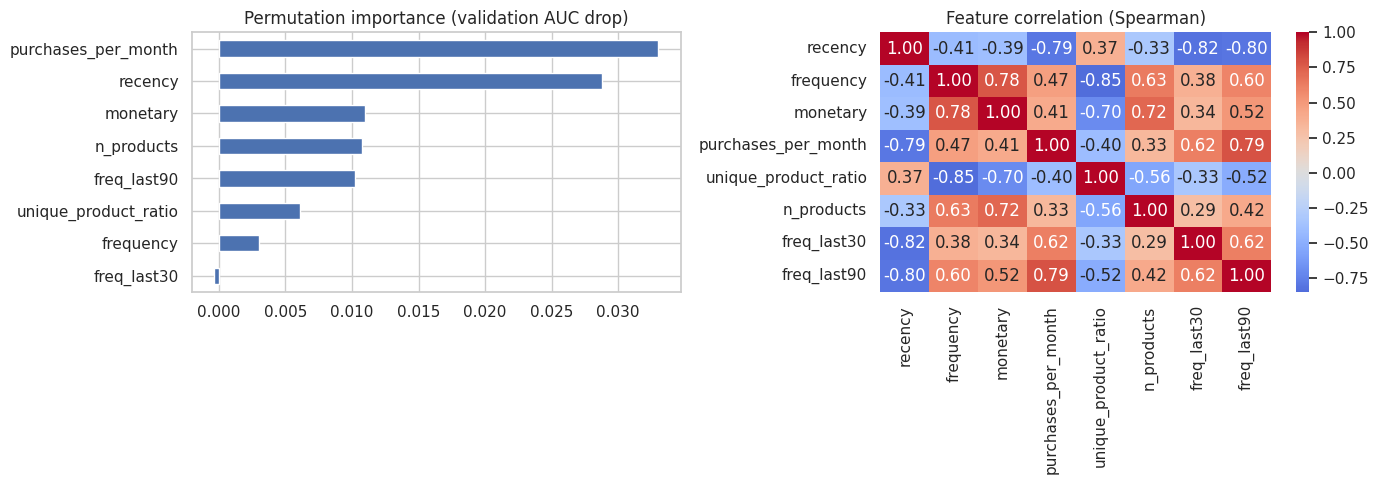

In [ ]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight='balanced',
                            n_jobs=-1, random_state=42).fit(train[SET_B], ytr)
pim = permutation_importance(rf, val[SET_B], yva, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pim.importances_mean, index=SET_B).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.plot.barh(ax=ax[0]); ax[0].set_title('Permutation importance (validation AUC drop)')
sns.heatmap(train[SET_B].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Feature correlation (Spearman)')
plt.tight_layout(); plt.savefig(OUT+'feature_importance.png', dpi=200, bbox_inches='tight'); plt.show()

Validation prevalence (accuracy of always predicting the majority class): 0.658
          Model     FeatureSet  n_features  Threshold  Fit_s  Accuracy  \
0         Dummy         A: RFM           3       0.50   0.01    0.6584   
1        LogReg         A: RFM           3       0.50   0.13    0.7429   
2        LogReg  B: 8 features           8       0.51   0.18    0.7620   
3  RandomForest         A: RFM           3       0.46  11.81    0.7216   
4  RandomForest  B: 8 features           8       0.43  11.78    0.7320   
5       XGBoost         A: RFM           3       0.49   0.96    0.7501   
6       XGBoost  B: 8 features           8       0.45   4.47    0.7520   

   Precision  Recall      F1  ROC_AUC  PR_AUC  
0     0.0000  0.0000  0.0000   0.5000  0.3416  
1     0.6110  0.6808  0.6440   0.8044  0.7039  
2     0.6527  0.6480  0.6503   0.8099  0.7173  
3     0.5764  0.6977  0.6313   0.7855  0.6872  
4     0.5909  0.6998  0.6408   0.8021  0.7193  
5     0.6258  0.6676  0.6460   0.8027  

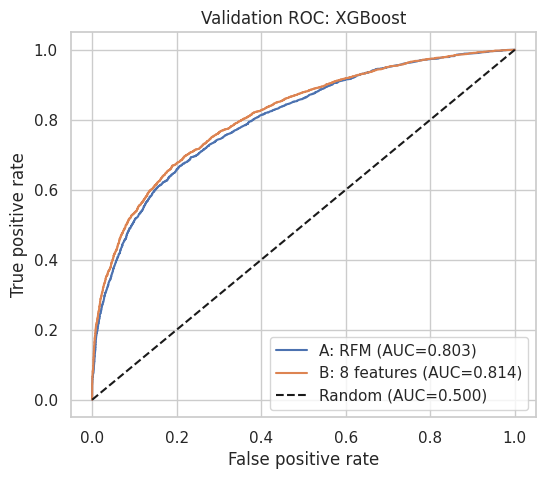

In [ ]:
def make_model(name):
    if name == 'Dummy': return DummyClassifier(strategy='prior')
    if name == 'LogReg':
        return Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))])
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight='balanced', n_jobs=-1, random_state=42)
    if name == 'XGBoost':
        return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, scale_pos_weight=spw,
                             eval_metric='logloss', random_state=42, n_jobs=-1)

def best_threshold(y, p):                          # chosen on VALIDATION only
    grid = np.arange(0.20, 0.81, 0.01)
    return grid[np.argmax([f1_score(y, p >= t) for t in grid])]

def scores(y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred), F1=f1_score(y, pred),
                ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p))

print('Validation prevalence (accuracy of always predicting the majority class):', round(max(yva.mean(), 1 - yva.mean()), 3))
FSETS = {'A: RFM': SET_A, 'B: 8 features': SET_B}
rows, vprob = [], {}
for mname, sets in [('Dummy', {'A: RFM': SET_A})] + [(m, FSETS) for m in ['LogReg', 'RandomForest', 'XGBoost']]:
    for sname, fs in sets.items():
        mdl = make_model(mname)
        t = time.time(); mdl.fit(train[fs], ytr); fit_s = time.time() - t
        p = mdl.predict_proba(val[fs])[:, 1]; vprob[(mname, sname)] = p
        thr = best_threshold(yva, p) if mname != 'Dummy' else 0.5
        rows.append(dict(Model=mname, FeatureSet=sname, n_features=len(fs), Threshold=round(thr, 2),
                         Fit_s=round(fit_s, 2), **scores(yva, p, thr)))
vt = pd.DataFrame(rows).round(4); print(vt)

# rule: among results within 0.005 AUC of the best, prefer the fewest features
real = vt[vt.Model != 'Dummy']
ok = real[real.ROC_AUC >= real.ROC_AUC.max() - 0.005].sort_values(['n_features', 'ROC_AUC'], ascending=[True, False])
SEL = ok.iloc[0]; print('\nSelected:', SEL.Model, SEL.FeatureSet, '| validation threshold:', SEL.Threshold)
sel_model, sel_set = SEL.Model, FSETS[SEL.FeatureSet]

plt.figure(figsize=(6, 5))
for sname in FSETS:
    p = vprob[(sel_model, sname)]; fpr, tpr, _ = roc_curve(yva, p)
    plt.plot(fpr, tpr, label=f'{sname} (AUC={roc_auc_score(yva, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title(f'Validation ROC: {sel_model}')
plt.legend(loc='lower right'); plt.savefig(OUT+'roc_validation.png', dpi=200, bbox_inches='tight'); plt.show()

Test prevalence: 0.428
Accuracy     0.7322
Precision    0.7376
Recall       0.5809
F1           0.6500
ROC_AUC      0.7966
PR_AUC       0.7681
dtype: float64
              precision    recall  f1-score   support

           0       0.73      0.85      0.78      2988
           1       0.74      0.58      0.65      2236

    accuracy                           0.73      5224
   macro avg       0.73      0.71      0.72      5224
weighted avg       0.73      0.73      0.73      5224



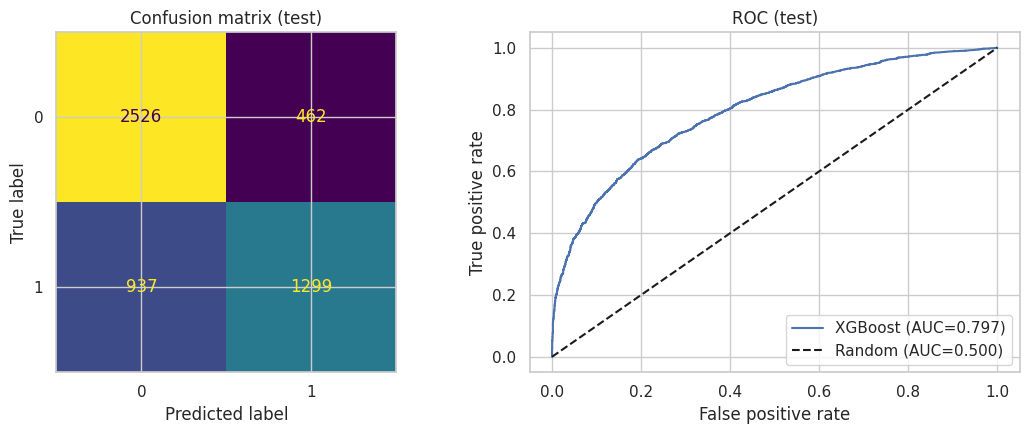

['/content/drive/MyDrive/retail_outputs/final_model.joblib']

In [ ]:
trval = pd.concat([train, val])
final = make_model(sel_model).fit(trval[sel_set], trval.target)
p = final.predict_proba(test[sel_set])[:, 1]
thr = float(SEL.Threshold)                    # fixed from validation, not re-tuned on test
pred = (p >= thr).astype(int)

print('Test prevalence:', round(yte.mean(), 3))
print(pd.Series(scores(yte, p, thr)).round(4))
print(classification_report(yte, pred))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(yte, pred, ax=ax[0], colorbar=False); ax[0].set_title('Confusion matrix (test)')
fpr, tpr, _ = roc_curve(yte, p)
ax[1].plot(fpr, tpr, label=f'{sel_model} (AUC={roc_auc_score(yte, p):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.500)')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend(loc='lower right'); ax[1].set_title('ROC (test)')
plt.tight_layout(); plt.savefig(OUT+'final_test.png', dpi=200, bbox_inches='tight'); plt.show()
joblib.dump(dict(model=final, features=sel_set, threshold=thr), OUT+'final_model.joblib')

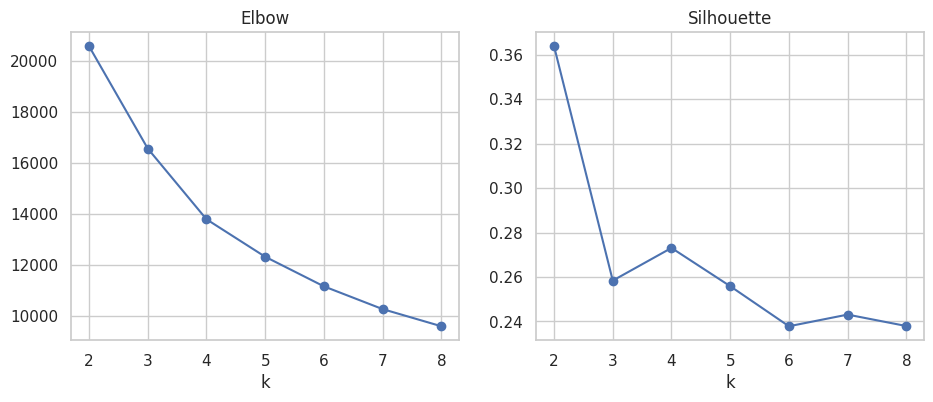

Silhouette by k: {2: 0.364, 3: 0.258, 4: 0.273, 5: 0.256, 6: 0.238, 7: 0.243, 8: 0.238}


In [ ]:
snap_end = LAST.ceil('D')
cf = build_features(purch, snap_end)                  # current state of every customer
cf['aov_mean'] = cf.monetary / cf.frequency           # average order value
CL = ['recency', 'frequency', 'monetary', 'aov_mean', 'freq_last90', 'n_products']
Xs = StandardScaler().fit_transform(np.log1p(cf[CL]))    # log reduces skew; nobody is deleted

ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.savefig(OUT+'elbow_silhouette.png', dpi=200, bbox_inches='tight'); plt.show()
print('Silhouette by k:', {k: round(float(s), 3) for k, s in zip(ks, sil)})

In [ ]:
K = 4   # k=4 gives groups that need different actions
cf['cluster'] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xs)

prof = cf.groupby('cluster')[CL].median()
# names come from the profile (guaranteed unique): most frequent = loyal; most recent of the rest = active;
# of the remaining two, the one with fewer invoices = one-time, the other = lapsed
loyal = prof.frequency.idxmax(); rest = prof.drop(loyal)
active = rest.recency.idxmin(); rest = rest.drop(active)
one_time = rest.frequency.idxmin(); lapsed = [c for c in rest.index if c != one_time][0]
NAMES = {loyal: 'Loyal high-value', active: 'Active regulars', one_time: 'One-time / inactive', lapsed: 'Lapsed mid-value'}

profile = prof.round(1)
profile['customers'] = cf.cluster.value_counts().sort_index()
profile['pct'] = (100 * profile.customers / len(cf)).round(1)
profile.insert(0, 'segment', profile.index.map(NAMES))
print(profile)                       # READ this table and check each name fits its numbers
cf['segment'] = cf.cluster.map(NAMES)

# rule-based RFM segmentation for comparison (terciles)
sc = lambda s, rev=False: pd.qcut(s.rank(method='first', ascending=not rev), 3, labels=[1, 2, 3]).astype(int)
cf['R'], cf['F'], cf['M'] = sc(cf.recency, True), sc(cf.frequency), sc(cf.monetary)
def rule(r):
    if r.F == 3 and r.R >= 2: return 'Loyal'
    if r.F >= 2 and r.R == 1: return 'At risk / declining'
    if r.M == 3:              return 'High-spend'
    if r.R == 1:              return 'Inactive'
    return 'Regular'
cf['rule_segment'] = cf.apply(rule, axis=1)
print('\nRule-based segment sizes:'); print(cf.rule_segment.value_counts())
print('Agreement with K-Means (adjusted Rand index):', round(adjusted_rand_score(cf.rule_segment, cf.cluster), 3))

                     segment  recency  frequency  monetary  aov_mean  \
cluster                                                                
0        One-time / inactive    390.3        1.0     205.3     150.6   
1            Active regulars     30.6        3.0     892.0     273.5   
2           Loyal high-value     16.4       13.0    4737.2     378.4   
3           Lapsed mid-value    309.5        3.0    1018.4     353.3   

         freq_last90  n_products  customers   pct  
cluster                                            
0                0.0        12.0       1547  26.4  
1                1.0        48.0       1511  25.8  
2                2.0       175.0       1189  20.3  
3                0.0        51.0       1605  27.4  

Rule-based segment sizes:
rule_segment
Regular                1848
Loyal                  1792
Inactive               1136
At risk / declining     792
High-spend              284
Name: count, dtype: int64
Agreement with K-Means (adjusted Rand index): 0.2

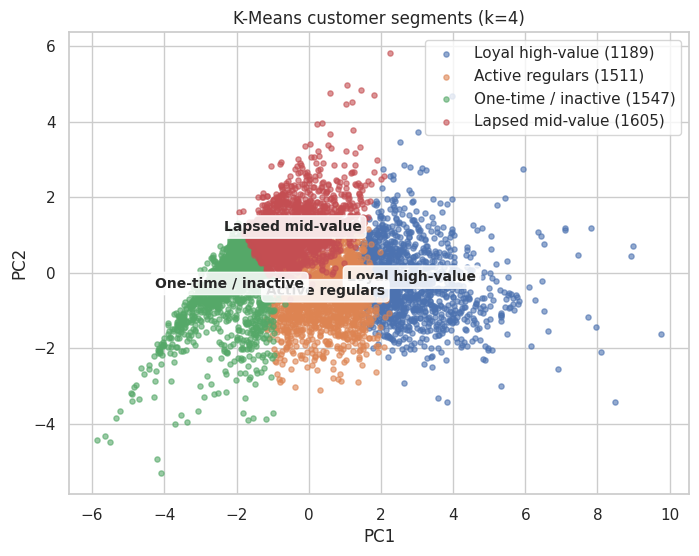

In [ ]:
pc = PCA(n_components=2, random_state=42).fit_transform(Xs)      # 2D view for drawing only
cf['pc1'], cf['pc2'] = pc[:, 0], pc[:, 1]
plt.figure(figsize=(8, 6))
for c, name in NAMES.items():
    m = cf.cluster == c
    plt.scatter(cf.pc1[m], cf.pc2[m], s=14, alpha=0.6, label=f'{name} ({m.sum()})')
    plt.text(cf.pc1[m].mean(), cf.pc2[m].mean(), name, fontsize=10, fontweight='bold', ha='center',
             bbox=dict(boxstyle='round', fc='white', alpha=0.85))
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title(f'K-Means customer segments (k={K})'); plt.legend()
plt.savefig(OUT+'cluster_scatter.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
FREQ_PERCENTILE = 0.75
FREQ_MIN = max(2, int(np.ceil(cf.frequency.quantile(FREQ_PERCENTILE))))

b = pd.cut(val.frequency, [0, 1, 2, 3, 5, 8, 1e9], labels=['1', '2', '3', '4-5', '6-8', '9+'])
print('Repeat rate by invoice count (validation):')
print(val.groupby(b).target.agg(['mean', 'size']).round(3).rename(columns={'mean': 'repeat_rate'}))
print(f'\nLoyalty rule: >= {FREQ_MIN} invoices -> {100*(cf.frequency >= FREQ_MIN).mean():.1f}% of customers')

lv = val[val.frequency >= FREQ_MIN]
rb = pd.cut(lv.recency, [0, 30, 90, 180, 270, 1e9], labels=['0-30', '31-90', '91-180', '181-270', '271+'])
print('\nRepeat rate of loyal customers by days since last order (validation):')
print(lv.groupby(rb).target.agg(['size', 'mean']).round(3).rename(columns={'mean': 'repeat_rate'}))

Repeat rate by invoice count (validation):
           repeat_rate  size
frequency                   
1                0.131  3098
2                0.215  1680
3                0.315  1095
4-5              0.387  1381
6-8              0.547  1058
9+               0.782  1393

Loyalty rule: >= 7 invoices -> 25.8% of customers

Repeat rate of loyal customers by days since last order (validation):
         size  repeat_rate
recency                   
0-30      973        0.838
31-90     593        0.750
91-180    305        0.502
181-270   101        0.218
271+       35        0.029


In [ ]:
# ---- BUSINESS RULE settings (separate from the model's classification threshold) ----
MON_HI    = cf.monetary.quantile(0.75)     # "high-value" spend level
RISK_PROB = thr                            # below the validated model threshold = at risk of not returning
DORMANT_DAYS = 270                         # set from the recency table in Cell 14
HOLDOUT_FRAC = 0.15                        # share of dormant customers kept as a no-offer control group
cf['holdout'] = np.random.RandomState(42).rand(len(cf)) < HOLDOUT_FRAC

cf['prob'] = final.predict_proba(cf[sel_set])[:, 1]

def decide(r):
    loyal, big, at_risk = r.frequency >= FREQ_MIN, r.monetary >= MON_HI, r.prob < RISK_PROB
    if loyal and r.recency > DORMANT_DAYS:
        if r.holdout: return 'Control', 'Dormant control group: no offer (used to measure discount effect)'
        return 'Eligible', 'Dormant win-back discount'
    if loyal and big and not at_risk: return 'Eligible', 'VIP offer (early access, tier perk)'
    if loyal and big:                 return 'Eligible', 'High-value win-back offer'
    if loyal and not at_risk:         return 'Eligible', 'Loyalty reward (points, no deep discount)'
    if loyal:                         return 'Eligible', 'Win-back discount'
    if at_risk:                       return 'Not eligible', 'Low-cost re-engagement message (no discount)'
    return 'Not eligible', 'No offer; monitor'
cf[['discount_eligibility', 'action']] = cf.apply(lambda r: pd.Series(decide(r)), axis=1)

summary = cf.groupby('segment').agg(customers=('recency', 'size'), median_recency=('recency', 'median'),
              median_freq=('frequency', 'median'), median_spend=('monetary', 'median'), mean_prob=('prob', 'mean'),
              eligible=('discount_eligibility', lambda s: (s == 'Eligible').sum()))
summary['pct'] = (100 * summary.customers / len(cf)).round(1)
print(summary.round(2)); print('\n', cf.action.value_counts())

                     customers  median_recency  median_freq  median_spend  \
segment                                                                     
Active regulars           1511           30.56          3.0        891.98   
Lapsed mid-value          1605          309.52          3.0       1018.42   
Loyal high-value          1189           16.44         13.0       4737.23   
One-time / inactive       1547          390.33          1.0        205.30   

                     mean_prob  eligible   pct  
segment                                         
Active regulars           0.50       178  25.8  
Lapsed mid-value          0.23       238  27.4  
Loyal high-value          0.79      1071  20.3  
One-time / inactive       0.14         9  26.4  

 action
Low-cost re-engagement message (no discount)                         3405
VIP offer (early access, tier perk)                                  1079
No offer; monitor                                                     939
Loyalty rewa

In [ ]:
MIN_INV = 3                    # need >= 3 invoices for a usable pattern
DUE_FROM, DUE_TO = 1.0, 3.0    # "due" when days since last order is 1x to 3x the usual gap

def reorder_status(d):
    usual_gap = (30 / d.purchases_per_month).clip(lower=1)     # approx. days between orders
    ratio = d.recency / usual_gap
    s = np.select([d.frequency < MIN_INV, ratio < DUE_FROM, ratio <= DUE_TO],
                  ['No pattern yet', 'Not due yet', 'Due now'], default='Lapsed')
    return pd.Series(s, index=d.index)

val['reorder_status'] = reorder_status(val).values        # evidence on validation snapshots
print(val.groupby('reorder_status').target.agg(['size', 'mean']).rename(columns={'mean': 'repeat_rate'}).round(3))

cf['reorder_status'] = reorder_status(cf)
cf['reorder_action'] = np.where(cf.reorder_status != 'Due now', '-',
                         np.where(cf.prob < thr, 'Reminder + small incentive', 'Reminder only (no discount)'))
print(cf.reorder_status.value_counts())

                size  repeat_rate
reorder_status                   
Due now         2279        0.453
Lapsed           381        0.268
No pattern yet  4778        0.161
Not due yet     2267        0.624
reorder_status
No pattern yet    2563
Not due yet       2053
Due now            985
Lapsed             251
Name: count, dtype: int64


In [ ]:
MIN_SUPPORT, K_REC = 20, 5      # product must appear on >= 20 invoices; recommend 5 items

def fit_cooc(cutoff):
    """Co-purchase similarity using only invoices BEFORE the cutoff."""
    p = purch.loc[purch.InvoiceDate < cutoff, ['Invoice', 'StockCode']].drop_duplicates()
    n_i = p.StockCode.value_counts(); items = n_i[n_i >= MIN_SUPPORT].index
    p = p[p.StockCode.isin(items)]
    inv = pd.Categorical(p.Invoice); prod = pd.Categorical(p.StockCode, categories=items)
    B = sparse.csr_matrix((np.ones(len(p)), (inv.codes, prod.codes)), shape=(len(inv.categories), len(items)))
    co = (B.T @ B).toarray(); cnt = np.diag(co).copy(); np.fill_diagonal(co, 0)
    return pd.DataFrame(co / np.sqrt(np.outer(cnt, cnt)), index=items, columns=items), cnt   # cosine similarity

def basket(d, customers, items):
    d = d[['CustomerID', 'StockCode']].drop_duplicates()
    d = d[d.CustomerID.isin(customers) & d.StockCode.isin(items)]
    r = pd.Index(customers).get_indexer(d.CustomerID); c = pd.Index(items).get_indexer(d.StockCode)
    m = np.zeros((len(customers), len(items)), dtype=bool); m[r, c] = True
    return m

def top_k(scores, bought, k):
    return np.argsort(-np.where(bought, -np.inf, scores), axis=1)[:, :k]     # never recommend what they own

# hold-out check at the test cutoff
t0 = TEST[0]; sim, cnt = fit_cooc(t0); items = sim.index; custs = snap[t0].index
U = basket(purch[purch.InvoiceDate < t0], custs, items)
F = basket(purch[(purch.InvoiceDate >= t0) & (purch.InvoiceDate < t0 + HORIZON)], custs, items)
F_new = F & ~U; has_new = F_new.any(axis=1)
rec = top_k(U.astype('float32') @ sim.values.astype('float32'), U, K_REC)
pop = top_k(np.tile(cnt.astype('float32'), (len(custs), 1)), U, K_REC)       # baseline: most popular items
row = np.arange(len(custs))[:, None]
print(f'Customers who bought a NEW product in the window: {has_new.sum()}')
print(f'Hit rate @{K_REC}  co-purchase: {F_new[row, rec].any(axis=1)[has_new].mean():.3f} | '
      f'popularity baseline: {F_new[row, pop].any(axis=1)[has_new].mean():.3f}')

# recommendations for current customers (all history)
sim_all, _ = fit_cooc(snap_end); items_all = sim_all.index
U_all = basket(purch, cf.index, items_all)
sc_all = U_all.astype('float32') @ sim_all.values.astype('float32')
top = top_k(sc_all, U_all, 3)
desc = purch.groupby('StockCode').Description.agg(lambda s: s.mode().iat[0])
cf['rec_products'] = [' | '.join(desc[items_all[j]] for j in top[i] if sc_all[i, j] > 0) for i in range(len(cf))]

Customers who bought a NEW product in the window: 2116
Hit rate @5  co-purchase: 0.264 | popularity baseline: 0.164


In [ ]:
pd.set_option('display.max_colwidth', 70)
camp = cf.reset_index()[['CustomerID', 'recency', 'frequency', 'monetary', 'prob', 'segment', 'reorder_status',
                         'reorder_action', 'rec_products', 'discount_eligibility', 'action']]
camp.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Repeat_Prob', 'Segment', 'Reorder_Status',
                'Reorder_Action', 'Suggested_Products', 'Discount_Eligibility', 'Loyalty_Action']
camp[['Recency', 'Monetary', 'Repeat_Prob']] = camp[['Recency', 'Monetary', 'Repeat_Prob']].round(2)
camp.to_csv(OUT+'campaign_list.csv', index=False)

due = camp[camp.Reorder_Status == 'Due now'].sort_values('Monetary', ascending=False)
print(f'Due now: {len(due)} customers ({100*len(due)/len(camp):.1f}%)'); print(due.Reorder_Action.value_counts())



Due now: 985 customers (16.8%)
Reorder_Action
Reminder + small incentive     601
Reminder only (no discount)    384
Name: count, dtype: int64


In [ ]:
def offer_for(cid):
    r = camp[camp.CustomerID == int(cid)]
    if r.empty: print('Customer not found'); return
    r = r.iloc[0]
    print(f'Customer {int(cid)} | {r.Segment} | {r.Frequency} invoices | last order {r.Recency:.0f} days ago')
    print(f'Repeat probability: {r.Repeat_Prob:.2f} | Reorder status: {r.Reorder_Status}')
    print(f'Reorder action : {r.Reorder_Action}'); print(f'Loyalty action : {r.Loyalty_Action}')
    print(f'Suggest products: {r.Suggested_Products}')

CUSTOMER_ID = 17850      # <-- change to any CustomerID
offer_for(CUSTOMER_ID)

Customer 17850 | Loyal high-value | 155 invoices | last order 372 days ago
Repeat probability: 0.06 | Reorder status: Lapsed
Reorder action : -
Loyalty action : Dormant win-back discount
Suggest products: JUMBO BAG RED RETROSPOT | LUNCH BAG SUKI  DESIGN  | LUNCH BAG PINK POLKADOT
